<a href="https://colab.research.google.com/github/asetya/BigData/blob/master/edge.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ==============================================================================
# Classical Edge Detection Suite for Arbitrary Input Images
# (Sobel, Prewitt, Laplacian, LoG / Marr-Hildreth, Canny)
# Compatible with Google Colab and Local Python Environments
# ==============================================================================

import urllib.request
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import convolve, gaussian_filter

# ------------------------------------------------------------------------------
# 1. Flexible Input Handler
# ------------------------------------------------------------------------------

def load_input_image(source):
    """
    Loads an image from:
    - Web URL (http:// or https://)
    - Raw bytes (e.g. from google.colab.files.upload())
    - Local file path / Google Drive path ('/content/image.jpg')
    - Existing NumPy array (RGB/BGR/Grayscale)

    Returns:
    - img_rgb: 3-channel RGB image for reference display
    - img_gray: Grayscale 8-bit image for edge operators
    """
    if isinstance(source, np.ndarray):
        img_bgr = source.copy()
        if len(img_bgr.shape) == 2:
            img_bgr = cv2.cvtColor(img_bgr, cv2.COLOR_GRAY2BGR)
    elif isinstance(source, bytes):
        nparr = np.frombuffer(source, np.uint8)
        img_bgr = cv2.imdecode(nparr, cv2.IMREAD_COLOR)
    elif isinstance(source, str) and (source.startswith('http://') or source.startswith('https://')):
        req = urllib.request.Request(source, headers={'User-Agent': 'Mozilla/5.0'})
        with urllib.request.urlopen(req) as resp:
            nparr = np.frombuffer(resp.read(), np.uint8)
            img_bgr = cv2.imdecode(nparr, cv2.IMREAD_COLOR)
    elif isinstance(source, str):
        img_bgr = cv2.imread(source, cv2.IMREAD_COLOR)
    else:
        raise ValueError("Unsupported input format.")

    if img_bgr is None:
        raise ValueError(f"Could not decode image from source: {source}")

    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    return img_rgb, img_gray


# ------------------------------------------------------------------------------
# 2. Individual Classical Edge Detection Operators
# ------------------------------------------------------------------------------

def sobel_edge_detector(img_gray):
    """1st-Order Gradient with orthogonal smoothing (Sobel)."""
    Ix = cv2.Sobel(img_gray, cv2.CV_64F, 1, 0, ksize=3)
    Iy = cv2.Sobel(img_gray, cv2.CV_64F, 0, 1, ksize=3)
    mag = np.hypot(Ix, Iy)
    return (mag / (mag.max() + 1e-8) * 255).astype(np.uint8)


def prewitt_edge_detector(img_gray):
    """1st-Order Gradient with uniform box smoothing (Prewitt)."""
    Kx = np.array([[-1, 0, 1],
                   [-1, 0, 1],
                   [-1, 0, 1]], dtype=np.float64)
    Ky = np.array([[-1, -1, -1],
                   [ 0,  0,  0],
                   [ 1,  1,  1]], dtype=np.float64)

    Ix = convolve(img_gray.astype(np.float64), Kx)
    Iy = convolve(img_gray.astype(np.float64), Ky)
    mag = np.hypot(Ix, Iy)
    return (mag / (mag.max() + 1e-8) * 255).astype(np.uint8)


def laplacian_edge_detector(img_gray):
    """Pure 2nd-Order Differential Operator (Laplacian)."""
    lap = cv2.Laplacian(img_gray, cv2.CV_64F, ksize=3)
    lap_abs = np.abs(lap)
    return (lap_abs / (lap_abs.max() + 1e-8) * 255).astype(np.uint8)


def log_zero_crossing_detector(img_gray, sigma=1.5, threshold_ratio=0.03):
    """Laplacian of Gaussian (LoG / Marr-Hildreth) with zero-crossing thresholding."""
    smoothed = gaussian_filter(img_gray.astype(np.float64), sigma=sigma)
    log = cv2.Laplacian(smoothed, cv2.CV_64F, ksize=3)

    h, w = log.shape
    edges = np.zeros((h, w), dtype=np.uint8)
    thresh = threshold_ratio * (log.max() - log.min() + 1e-8)

    # Vectorized zero-crossing verification along horizontal and vertical axes
    # Horizontal zero crossing (left and right neighbors)
    h_cross = (log[:, :-2] * log[:, 2:] < 0) & (np.abs(log[:, :-2] - log[:, 2:]) > thresh)
    edges[:, 1:-1][h_cross] = 255

    # Vertical zero crossing (top and bottom neighbors)
    v_cross = (log[:-2, :] * log[2:, :] < 0) & (np.abs(log[:-2, :] - log[2:, :]) > thresh)
    edges[1:-1, :][v_cross] = 255

    return edges


def canny_edge_detector(img_gray, low_thresh=50, high_thresh=150):
    """Multi-stage Canny Edge Detector (Smoothing + Gradients + NMS + Hysteresis)."""
    return cv2.Canny(img_gray, low_thresh, high_thresh)


# ------------------------------------------------------------------------------
# 3. Execution Pipeline & Visual Comparison
# ------------------------------------------------------------------------------

def run_classical_edge_benchmark(image_source, canny_low=60, canny_high=140, log_sigma=1.5):
    """
    Executes all edge operators on any input source and plots the results side-by-side.
    """
    img_rgb, img_gray = load_input_image(image_source)

    # Compute all edge representations
    res_sobel = sobel_edge_detector(img_gray)
    res_prewitt = prewitt_edge_detector(img_gray)
    res_laplacian = laplacian_edge_detector(img_gray)
    res_log = log_zero_crossing_detector(img_gray, sigma=log_sigma)
    res_canny = canny_edge_detector(img_gray, low_thresh=canny_low, high_thresh=canny_high)

    # Visualization
    fig, axes = plt.subplots(2, 3, figsize=(18, 11), dpi=120)

    axes[0, 0].imshow(img_rgb)
    axes[0, 0].set_title(f"Input Image ({img_rgb.shape[1]}x{img_rgb.shape[0]})", fontsize=12)
    axes[0, 0].axis('off')

    axes[0, 1].imshow(res_sobel, cmap='gray')
    axes[0, 1].set_title("1. Sobel Gradient Magnitude", fontsize=12)
    axes[0, 1].axis('off')

    axes[0, 2].imshow(res_prewitt, cmap='gray')
    axes[0, 2].set_title("2. Prewitt Gradient Magnitude", fontsize=12)
    axes[0, 2].axis('off')

    axes[1, 0].imshow(res_laplacian, cmap='gray')
    axes[1, 0].set_title("3. Laplacian (Direct 2nd Order)", fontsize=12)
    axes[1, 0].axis('off')

    axes[1, 1].imshow(res_log, cmap='gray')
    axes[1, 1].set_title(f"4. Marr-Hildreth LoG ($\sigma={log_sigma}$)", fontsize=12)
    axes[1, 1].axis('off')

    axes[1, 2].imshow(res_canny, cmap='gray')
    axes[1, 2].set_title(f"5. Canny (T_low={canny_low}, T_high={canny_high})", fontsize=12)
    axes[1, 2].axis('off')

    plt.tight_layout()
    plt.show()

    return {
        "sobel": res_sobel,
        "prewitt": res_prewitt,
        "laplacian": res_laplacian,
        "log": res_log,
        "canny": res_canny
    }

<>:151: SyntaxWarning: invalid escape sequence '\s'
<>:151: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_728/2615096915.py:151: SyntaxWarning: invalid escape sequence '\s'
  axes[1, 1].set_title(f"4. Marr-Hildreth LoG ($\sigma={log_sigma}$)", fontsize=12)


Saving face.jpg to face.jpg
Analyzing: face.jpg


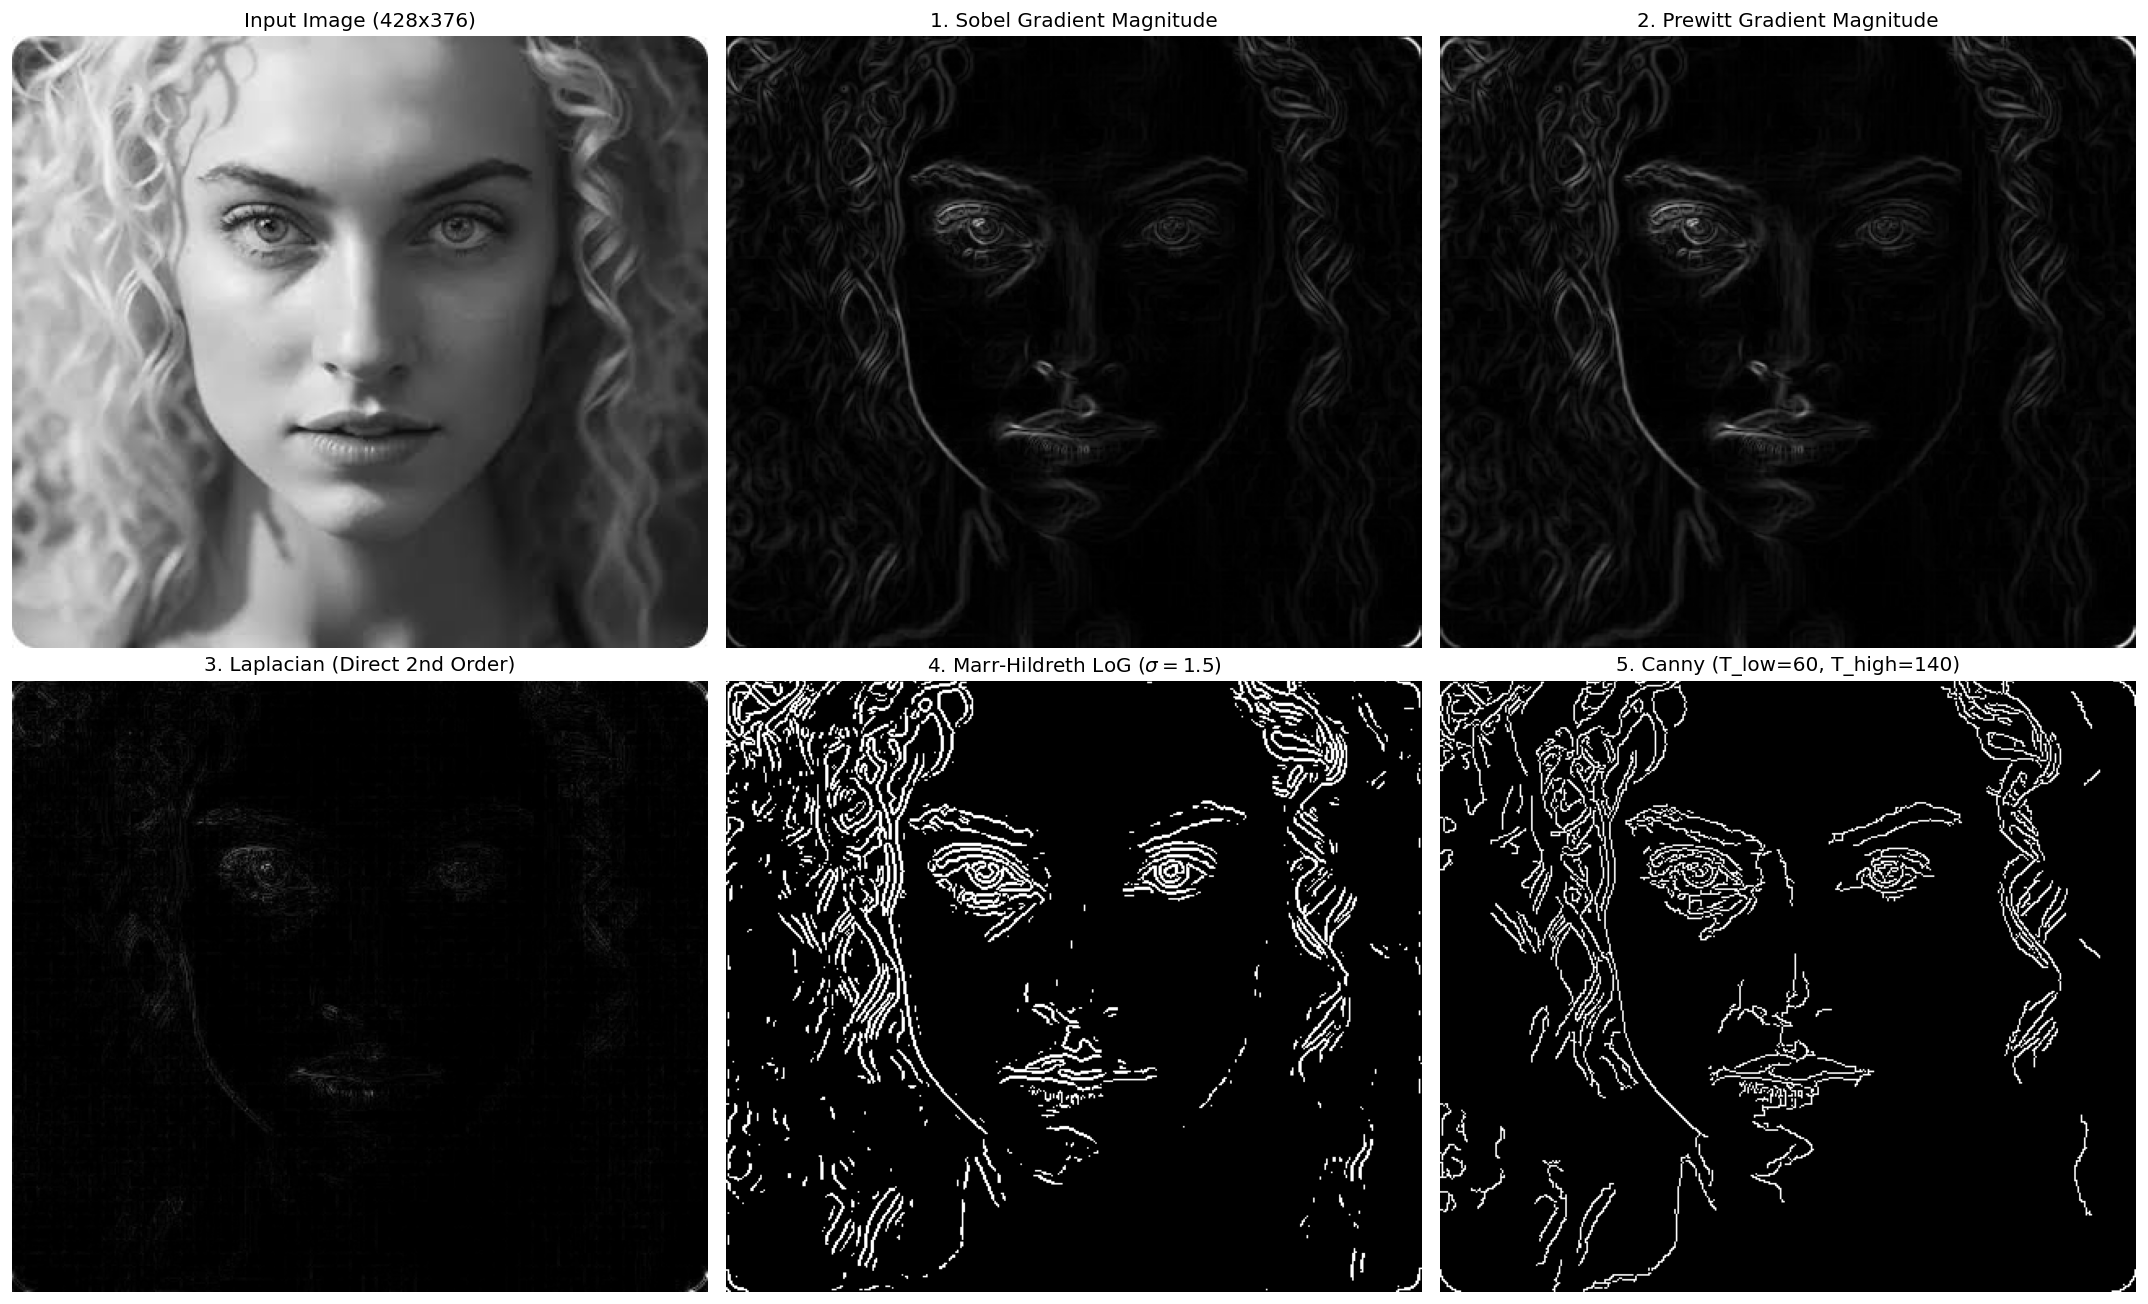

In [2]:
from google.colab import files

uploaded = files.upload()
for filename, file_bytes in uploaded.items():
    print(f"Analyzing: {filename}")
    results = run_classical_edge_benchmark(file_bytes)